# Group 9: Disha's data and training (Colab)

**Before you start**
1. Upload `group9_disha.zip` to **My Drive** (not inside a folder). Do not unzip it.
2. In Colab: **Runtime → Change runtime type → T4 GPU → Save**.
3. Run the cells **in order**, from top to bottom (Shift + Enter).

**Every time you come back:** turn on the GPU again, then run cells 1 to 4, then jump to the step you need.
Everything is saved in your Drive folder `group9`, so a disconnect loses nothing.

## 1. Check the GPU

In [1]:
import torch
if torch.cuda.is_available():
    print("GPU ready:", torch.cuda.get_device_name(0))
else:
    print("NO GPU! Go to Runtime -> Change runtime type -> T4 GPU -> Save, then run this cell again.")

GPU ready: NVIDIA A100-SXM4-40GB


## 2. Connect Google Drive
A pop-up asks for permission: click **Connect to Google Drive** and allow.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Unzip the code (first time only) and go into the folder
Leave `UPDATE_CODE = False`. Set it to `True` only when you upload a newer zip; your results and splits are never in the zip, so they are kept.

In [3]:
import os, subprocess, json
from IPython.display import Image, display
UPDATE_CODE = False

BASE = "/content/drive/MyDrive/DeepLearning"      # the folder that holds your zip
ZIP  = f"{BASE}/group9_disha.zip"
REPO = f"{BASE}/group9"
if not os.path.exists(REPO) or UPDATE_CODE:
    assert os.path.exists(ZIP), f"Zip not found at {ZIP}"
    subprocess.run(["unzip", "-q", "-o", ZIP, "-d", BASE], check=True)   # unzip INTO the DeepLearning folder
    print("Code unzipped.")
os.chdir(REPO)
print("Working in:", os.getcwd())
print(sorted(os.listdir(".")))

Code unzipped.
Working in: /content/drive/MyDrive/DeepLearning/group9
['.gitignore', 'configs', 'docs', 'notebooks', 'results', 'scripts', 'src']


## 4. Install packages
Colab already has PyTorch; only two packages are missing.

In [4]:
!pip install -q datasets imagehash
print("Packages ready.")

Packages ready.


---
## STEP 1: Data audit and fixed split (run ONCE, tonight)
Downloads the dataset (about 1.2 GB) and takes about 5 to 15 minutes.
Expected: every count says **PASS**, 0 unreadable images, split **3551 / 444 / 444**.
If the split already exists, this cell skips itself.

In [5]:
if os.path.exists("configs/splits/product_split.csv"):
    print("The split already exists, so step 1 is done. (The split is made once and never remade.)")
else:
    !bash scripts/01_data.sh

Loading dataset ...
README.md: 100% 5.94k/5.94k [00:00<00:00, 3.05MB/s]

data/train-00000-of-00003.parquet: downloading bytes:  59% 146M/249M [00:01<00:00, 183MB/s, 7.56MB/s  ]  
data/train-00000-of-00003.parquet: downloading bytes:  82% 204M/249M [00:01<00:00, 254MB/s, 14.1MB/s  ]
data/train-00000-of-00003.parquet: reconstructing file:  54% 134M/249M [00:01<00:01, 114MB/s, 6.50MB/s  ]
data/train-00000-of-00003.parquet: downloading bytes: 100% 244M/244M [00:01<00:00, 141MB/s, 23.1MB/s  ]
data/train-00000-of-00003.parquet: reconstructing file: 100% 249M/249M [00:01<00:00, 144MB/s, 23.7MB/s  ]

data/train-00001-of-00003.parquet: downloading bytes:  96% 115M/119M [00:01<00:00, 125MB/s, 9.80MB/s  ] 
data/train-00001-of-00003.parquet: downloading bytes: 100% 115M/115M [00:01<00:00, 83.3MB/s, 10.9MB/s  ]
data/train-00001-of-00003.parquet: reconstructing file: 100% 119M/119M [00:01<00:00, 86.8MB/s, 11.5MB/s  ]

data/train-00002-of-00003.parquet: downloading bytes:  50% 393M/791M [00:01<00:00,

### Check the data results
These numbers go into `docs/dataset_card.md`.

Domains found: ['Art', 'Clipart', 'Product', 'Real World']
  total        15588 (expected 15588)  PASS
  Product       4439 (expected 4439)  PASS
  Real World    4357 (expected 4357)  PASS
  Art           2427 (expected 2427)  PASS
  Clipart       4365 (expected 4365)  PASS
Classes: 65 | 'Clock' class present: False
Unreadable images: 0
Product near-duplicates: {'hamming_threshold': 4, 'pairs': 422, 'exact_hash_pairs': 268, 'groups_with_2plus_images': 284, 'images_in_such_groups': 628, 'largest_group': 8, 'groups_with_conflicting_labels': 16}
Product vs Real World near-duplicate pairs: 14
Flagged samples to review: 457

Split:
  train  3551 (expected 3551)  PASS
  val     444 (expected 444)  PASS
  test    444 (expected 444)  PASS
Duplicate groups crossing splits: 0
  budgets seed 42: {'b10': 355, 'b25': 888, 'b50': 1776, 'b100': 3551}  nested=True
  budgets seed 123: {'b10': 355, 'b25': 888, 'b50': 1776, 'b100': 3551}  nested=True
  budgets seed 999: {'b10': 355, 'b25': 888, 'b50': 17

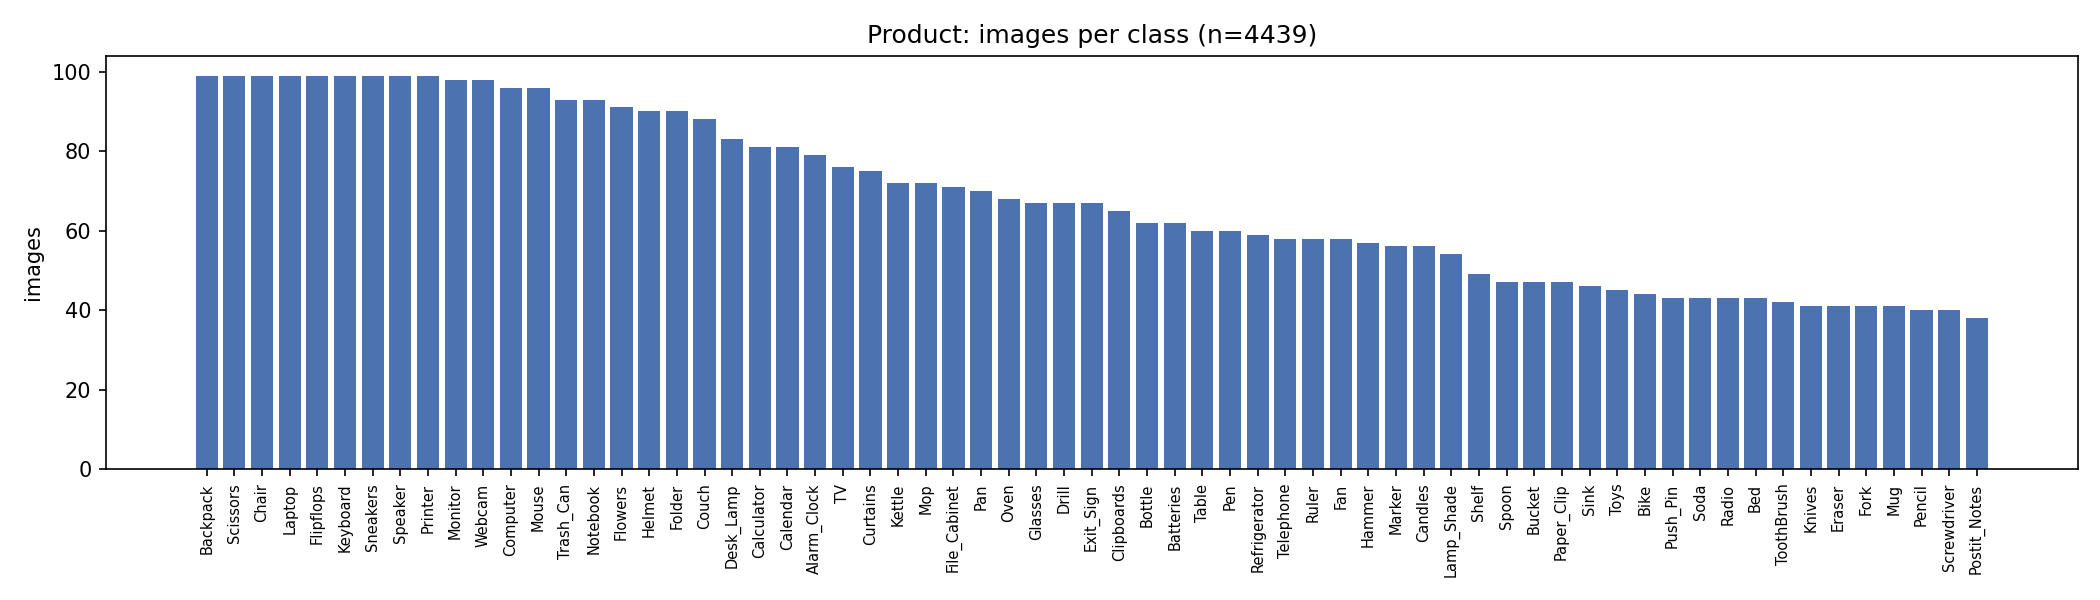

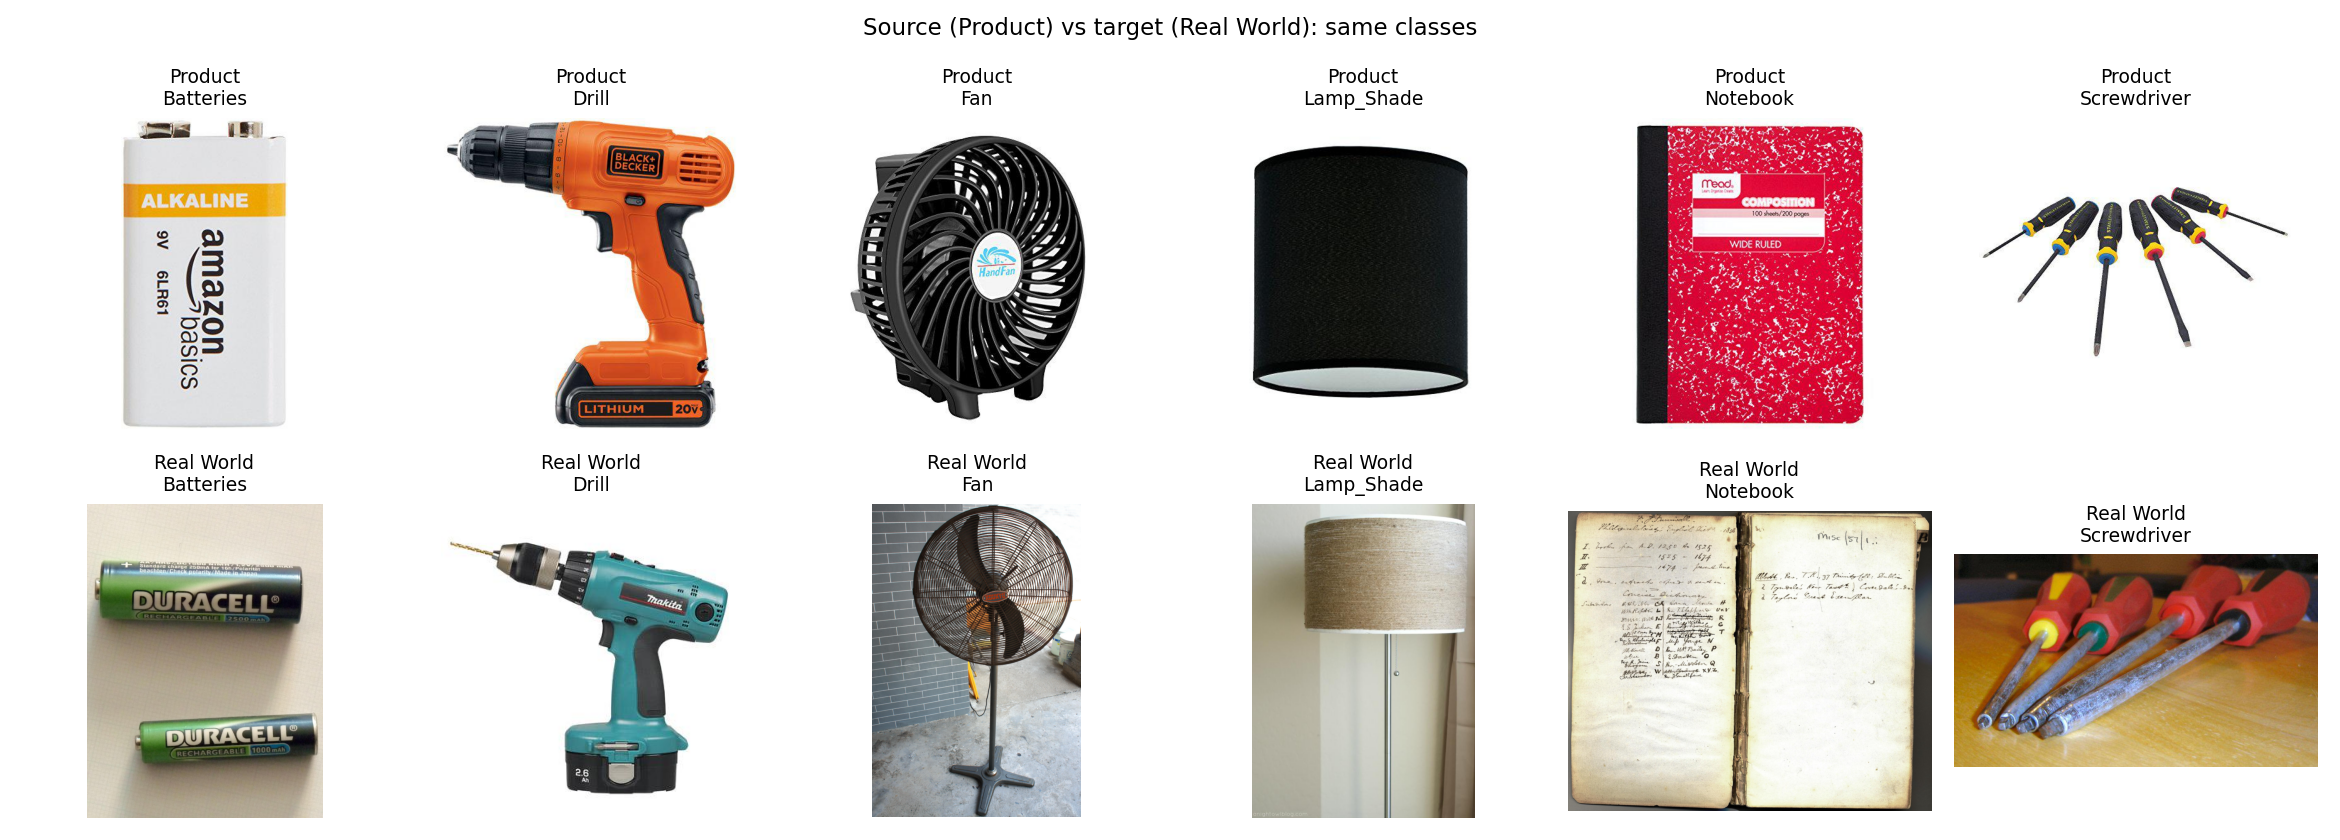

In [6]:
a = json.load(open("results/data_audit/summary.json"))
s = json.load(open("configs/splits/split_summary.json"))
print("Domains found:", a["domain_names_found"])
for k, v in a["count_checks"].items():
    print(f"  {k:<11} {v['found']:>6} (expected {v['expected']})  {v['status']}")
print("Classes:", a["classes"]["num_classes"], "| 'Clock' class present:", a["classes"]["has_class_named_clock"])
print("Unreadable images:", a["unreadable_images"]["count"])
print("Product near-duplicates:", a["product_near_duplicates"])
print("Product vs Real World near-duplicate pairs:", a["cross_domain_near_duplicates"]["pairs"])
print("Flagged samples to review:", a["flagged_samples"]["count"])
print("\nSplit:")
for k, v in s["checks"]["counts"].items():
    print(f"  {k:<5} {v['found']:>5} (expected {v['expected']})  {v['status']}")
print("Duplicate groups crossing splits:", s["checks"]["duplicate_groups_crossing_splits"])
for seed, b in s["budgets"].items():
    print(f"  budgets seed {seed}: {b['sizes']}  nested={b['nested']}")
display(Image("results/figures/product_class_distribution.png", width=900))
display(Image("results/figures/examples_product_vs_realworld.png", width=900))

**Now do by hand:** open the folder icon on the left → `drive/MyDrive/group9/outputs/audit/` and look at the near-duplicate pairs and examples
(wrong labels? identifiable people?). Write what you find in the dataset card.
Then commit `configs/splits/` and `results/data_audit/` to the team GitHub repo **by Nov 7**.

---
## STEP 2: Baseline linear probe (Nov 7)
Trains the linear probe (100% labels, seed 42), saves Product-validation predictions for Shruti, and draws its loss curve. About 10 to 20 minutes.

In [7]:
!bash scripts/02_baseline.sh

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 170MB/s]
Run lp_b100_s42: linear_probe, budget 100%, seed 42, lr 0.001, 3551 train / 444 val images, device cuda, amp True
  epoch  0  train_loss nan  val_loss 4.4219  val_acc 0.011  val_F1 0.005  (3.14 s)
  epoch  1  train_loss 2.3930  val_loss 1.2756  val_acc 0.739  val_F1 0.685  (5.63 s)
  epoch  2  train_loss 0.8676  val_loss 0.8501  val_acc 0.815  val_F1 0.801  (5.46 s)
  epoch  3  train_loss 0.5724  val_loss 0.7309  val_acc 0.815  val_F1 0.810  (5.62 s)
  epoch  4  train_loss 0.4395  val_loss 0.6124  val_acc 0.865  val_F1 0.857  (5.37 s)
  epoch  5  train_loss 0.3570  val_loss 0.5998  val_acc 0.847  val_F1 0.833  (5.57 s)
  epoch  6  train_loss 0.2929  val_loss 0.5549  val_acc 0.860  val_F1 0.856  (5.42 s)
  epoch  7  train_loss 0.2545  val_loss 0.5317  val_acc 0.851  val_F1 0.837  (5.62 s)
  epoch  8  train_loss 0.222

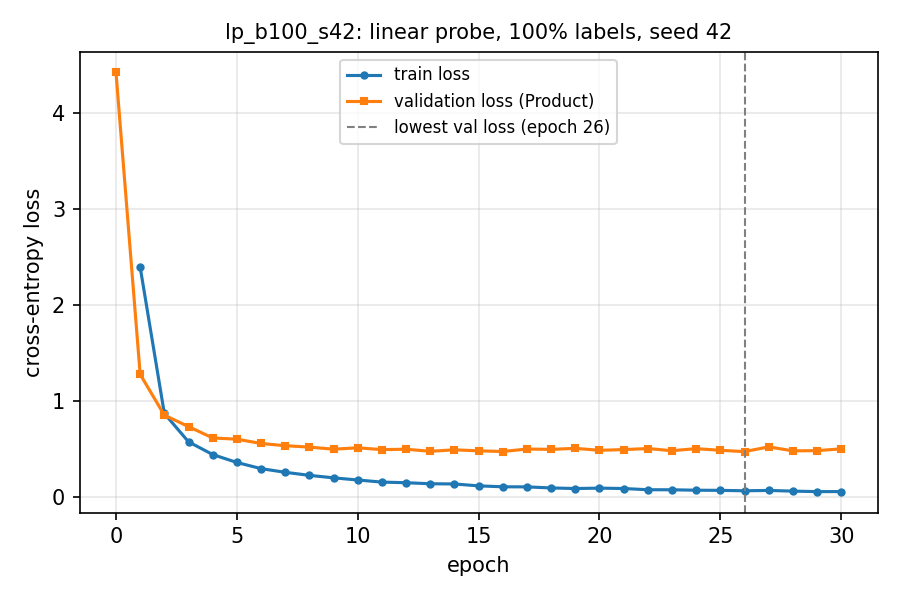

Predictions for Shruti are in outputs/predictions/
['lp_b100_s42_e26_val.csv']


In [8]:
display(Image("results/figures/loss_curve_lp_b100_s42.png", width=600))
print("Predictions for Shruti are in outputs/predictions/")
print(sorted(os.listdir("outputs/predictions")))

---
## STEP 2b: One fine-tuning run for the progress report (Nov 7 to 8)
Gives the training/validation loss curve for the progress report, and saved epochs Ruchika can test WeightWatcher on.
It uses lr 1e-4 because the pilot has not run yet. About 15 to 25 minutes.

Run progress_ft_b100_s42: finetune, budget 100%, seed 42, lr 0.0001, 3551 train / 444 val images, device cuda, amp True
  epoch  0  train_loss nan  val_loss 4.4219  val_acc 0.011  val_F1 0.005  (2.24 s)
  epoch  1  train_loss 2.3221  val_loss 1.2484  val_acc 0.745  val_F1 0.680  (6.04 s)
  epoch  2  train_loss 0.8595  val_loss 0.7845  val_acc 0.827  val_F1 0.806  (5.45 s)
  epoch  3  train_loss 0.4602  val_loss 0.6398  val_acc 0.845  val_F1 0.827  (5.64 s)
  epoch  4  train_loss 0.2740  val_loss 0.5811  val_acc 0.858  val_F1 0.839  (5.54 s)
  epoch  5  train_loss 0.1782  val_loss 0.5383  val_acc 0.856  val_F1 0.837  (5.49 s)
  epoch  6  train_loss 0.1129  val_loss 0.5203  val_acc 0.863  val_F1 0.853  (5.66 s)
  epoch  7  train_loss 0.0931  val_loss 0.4828  val_acc 0.876  val_F1 0.862  (5.48 s)
  epoch  8  train_loss 0.0650  val_loss 0.4866  val_acc 0.863  val_F1 0.848  (5.56 s)
  epoch  9  train_loss 0.0602  val_loss 0.4998  val_acc 0.872  val_F1 0.849  (5.57 s)
  epoch 10  train_loss 

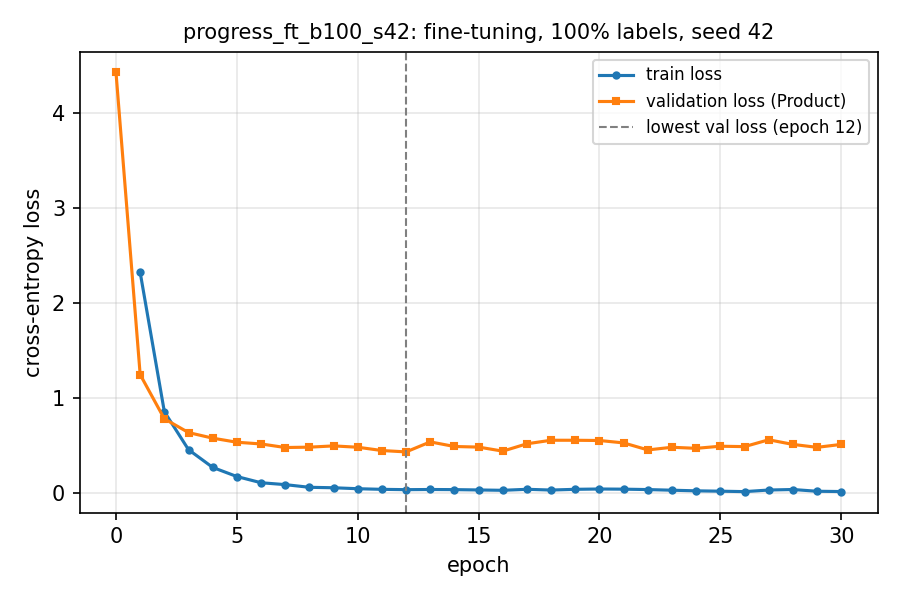

In [9]:
!python -m src.train.train --mode finetune --budget 100 --seed 42 --lr 1e-4 --run-name progress_ft_b100_s42 --resume
!python -m src.train.report_runs --runs progress_ft_b100_s42
display(Image("results/figures/loss_curve_progress_ft_b100_s42.png", width=600))

---
## STEP 3: Learning-rate pilot (Nov 9)
Two fine-tuning runs (lr 1e-4 and 3e-4), chosen on Product validation loss only. About 30 to 50 minutes.
If it disconnects, run cells 1 to 4 and this cell again: it continues.

In [10]:
!bash scripts/03_lr_pilot.sh
print(open("configs/lr_choice.json").read())


$ /usr/bin/python3 -m src.train.train --mode finetune --budget 100 --seed 42 --lr 0.0001 --run-name ft_b100_s42_lr0.0001 --out-root /content/drive/MyDrive/DeepLearning/group9/checkpoints/pilot --no-checkpoints --resume
Run ft_b100_s42_lr0.0001: finetune, budget 100%, seed 42, lr 0.0001, 3551 train / 444 val images, device cuda, amp True
  epoch  0  train_loss nan  val_loss 4.4219  val_acc 0.011  val_F1 0.005  (2.22 s)
  epoch  1  train_loss 2.3221  val_loss 1.2484  val_acc 0.745  val_F1 0.680  (5.8 s)
  epoch  2  train_loss 0.8595  val_loss 0.7845  val_acc 0.827  val_F1 0.806  (5.6 s)
  epoch  3  train_loss 0.4602  val_loss 0.6398  val_acc 0.845  val_F1 0.827  (5.75 s)
  epoch  4  train_loss 0.2740  val_loss 0.5811  val_acc 0.858  val_F1 0.839  (5.51 s)
  epoch  5  train_loss 0.1782  val_loss 0.5383  val_acc 0.856  val_F1 0.837  (5.57 s)
  epoch  6  train_loss 0.1129  val_loss 0.5203  val_acc 0.863  val_F1 0.853  (5.64 s)
  epoch  7  train_loss 0.0931  val_loss 0.4828  val_acc 0.876  

---
## STEP 4: All 24 runs (Nov 9 to 15)
Order: 100% → 10% → 25% → 50%. Safe to re-run after any disconnect: finished runs are skipped.

⚠️ **Storage:** all 12 fine-tuning runs need about 17 GB, but free Google Drive has 15 GB.
Check the space cell below first. To run part of the budgets, set `BUDGETS`, e.g. `"100 10"`.

In [11]:
BUDGETS = "100 10 25 50"   # e.g. "100" for the minimum viable project only
!bash scripts/04_train_all.sh --budgets {BUDGETS}

Fine-tuning learning rate from configs/lr_choice.json: 0.0001

$ /usr/bin/python3 -m src.train.train --mode finetune --budget 100 --seed 42 --resume --lr 0.0001
Run ft_b100_s42: finetune, budget 100%, seed 42, lr 0.0001, 3551 train / 444 val images, device cuda, amp True
  epoch  0  train_loss nan  val_loss 4.4219  val_acc 0.011  val_F1 0.005  (2.2 s)
  epoch  1  train_loss 2.3221  val_loss 1.2484  val_acc 0.745  val_F1 0.680  (5.9 s)
  epoch  2  train_loss 0.8595  val_loss 0.7845  val_acc 0.827  val_F1 0.806  (5.42 s)
  epoch  3  train_loss 0.4602  val_loss 0.6398  val_acc 0.845  val_F1 0.827  (5.55 s)
  epoch  4  train_loss 0.2740  val_loss 0.5811  val_acc 0.858  val_F1 0.839  (5.45 s)
  epoch  5  train_loss 0.1782  val_loss 0.5383  val_acc 0.856  val_F1 0.837  (5.58 s)
  epoch  6  train_loss 0.1129  val_loss 0.5203  val_acc 0.863  val_F1 0.853  (5.64 s)
  epoch  7  train_loss 0.0931  val_loss 0.4828  val_acc 0.876  val_F1 0.862  (5.65 s)
  epoch  8  train_loss 0.0650  val_loss 0.486

## Storage check (run any time)

In [12]:
!du -sh checkpoints 2>/dev/null || echo "no checkpoints yet"
!df -h /content/drive | tail -1

17G	checkpoints
drive           100G   47G   54G  47% /content/drive


## Training-time table (for your report section)

In [13]:
import pandas as pd
!python -m src.train.report_runs
pd.read_csv("results/training_time_summary.csv")

25 runs -> /content/drive/MyDrive/DeepLearning/group9/results/figures and /content/drive/MyDrive/DeepLearning/group9/results/training_time_summary.csv


,run_name,mode,budget_percent,seed,lr,n_train,trainable_params,epochs_done,train_seconds_total,mean_epoch_seconds,peak_gpu_mem_mb,gpu,lowest_val_loss_epoch,min_val_loss,finished
0,ft_b10_s42,finetune,10,42,0.0001,355,11209857,30,54.6,1.75,791.4,NVIDIA A100-SXM4-40GB,22,1.6023,True
1,ft_b10_s123,finetune,10,123,0.0001,355,11209857,30,58.1,1.86,791.4,NVIDIA A100-SXM4-40GB,30,1.4506,True
2,ft_b10_s999,finetune,10,999,0.0001,355,11209857,30,54.6,1.75,791.4,NVIDIA A100-SXM4-40GB,29,1.5643,True
3,ft_b25_s42,finetune,25,42,0.0001,888,11209857,30,74.3,2.40,790.7,NVIDIA A100-SXM4-40GB,26,0.8520,True
4,ft_b25_s123,finetune,25,123,0.0001,888,11209857,30,76.7,2.47,790.7,NVIDIA A100-SXM4-40GB,24,0.8398,True
5,ft_b25_s999,finetune,25,999,0.0001,888,11209857,30,73.6,2.38,790.7,NVIDIA A100-SXM4-40GB,24,0.9456,True
6,ft_b50_s42,finetune,50,42,0.0001,1776,11209857,30,120.2,3.93,791.3,NVIDIA A100-SXM4-40GB,16,0.6048,True
7,ft_b50_s123,finetune,50,123,0.0001,1776,11209857,30,120.2,3.92,791.3,NVIDIA A100-SXM4-40GB,29,0.5940,True
8,ft_b50_s999,finetune,50,999,0.0001,1776,11209857,30,119.4,3.90,791.3,NVIDIA A100-SXM4-40GB,14,0.6034,True
9,ft_b100_s42,finetune,100,42,0.0001,3551,11209857,30,172.3,5.67,792.4,NVIDIA A100-SXM4-40GB,12,0.4368,True
